Using Colab cache for faster access to the 'faces-age-detection-dataset' dataset.
Dataset path: /kaggle/input/faces-age-detection-dataset
          ID   Class
0    377.jpg  MIDDLE
1  17814.jpg   YOUNG
2  21283.jpg  MIDDLE
3  16496.jpg   YOUNG
4   4487.jpg  MIDDLE
Index(['ID', 'Class'], dtype='object')
Total images: 19906


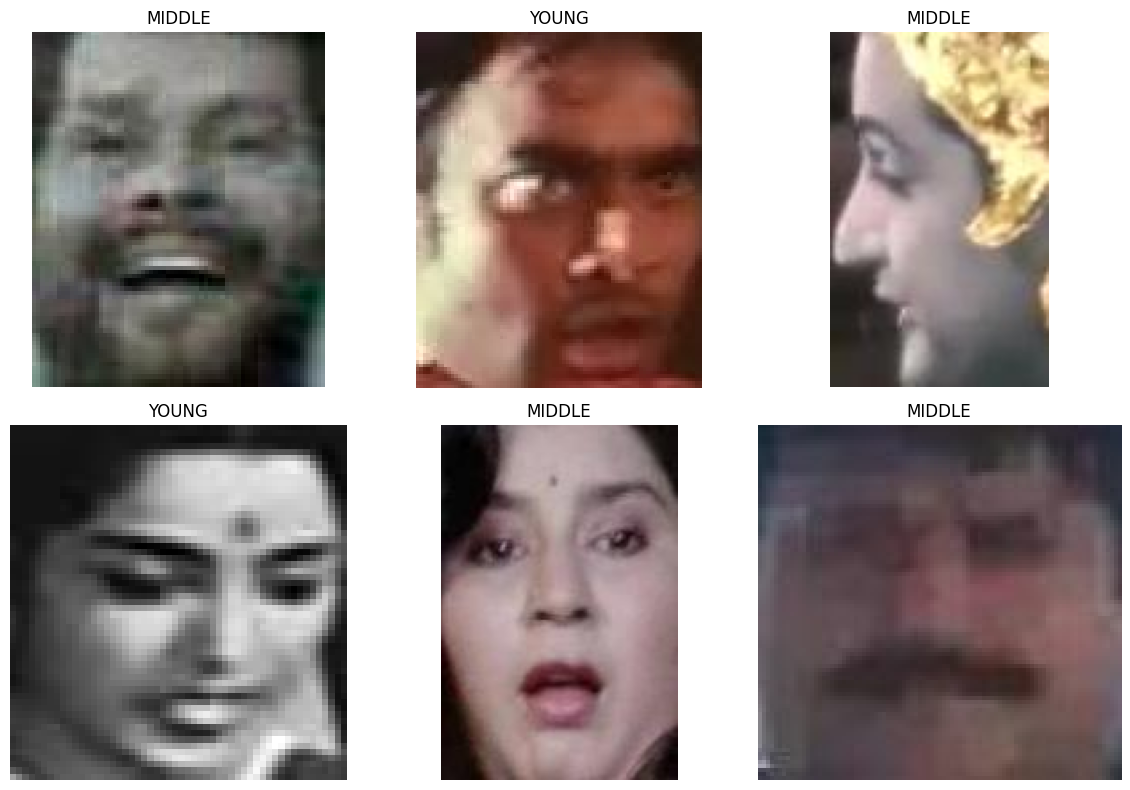

In [1]:
#Part A
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader, random_split
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

path = kagglehub.dataset_download(
    "arashnic/faces-age-detection-dataset"
)


print("Dataset path:", path)

# Find CSV file
csv_path = None

for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            csv_path = os.path.join(root, file)
            break
    if csv_path:
        break

df = pd.read_csv(csv_path)

print(df.head())
print(df.columns)

#find all images
image_files={}

for root,dirs,files in os.walk(path):
  for file in files:
    if file.lower().endswith((".jpg",".jpeg",".png")):
      image_files[file]=os.path.join(root,file)



#connect ID wiht image path
df['image_path'] = df["ID"].apply(
   lambda x: image_files.get(x)
)

df= df.dropna(subset=["image_path"]).reset_index(drop=True)

print("Total images:", len(df))

# Show sample images
plt.figure(figsize=(12, 8))

for i in range(6):
    image = Image.open(
        df.iloc[i]["image_path"]
    ).convert("RGB")

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(df.iloc[i]["Class"])
    plt.axis("off")

plt.tight_layout()
plt.show()













In [2]:


label_map={
    "YOUNG":0,
    "MIDDLE":1,
    "OLD":2
}


#image transformation

transform= transforms.Compose(
    [
        transforms.Resize((64,64)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.5] * 3,
            std=[0.5] * 3
        )

    ]
)






# Custom Dataset
class AgeClassification(Dataset):

    def __init__(self, dataframe, transform=None):

        super().__init__()

        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, idx):

        img_path = self.dataframe.iloc[idx]["image_path"]
        label_name = self.dataframe.iloc[idx]["Class"]

        image = Image.open(
            img_path
        ).convert("RGB")

        label = label_map[label_name]

        if self.transform:
            image = self.transform(image)

        return image, label


# Create dataset
dataset = AgeClassification(
    df,
    transform
)

print("Dataset size:", len(dataset))

Dataset size: 19906


In [3]:
# Setup
torch.manual_seed(42)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using Device:", device)


train_size= int(0.8* len(dataset))
val_size = len(dataset) - train_size


train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

print("Train size:", len(train_dataset))
print("Validation size:", len(val_dataset))


# Create DataLoaders
pin = True if device.type == "cuda" else False

train_loader= DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    pin_memory=pin
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    pin_memory=pin
)


Using Device: cuda
Train size: 15924
Validation size: 3982


In [4]:
class MyCNN(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(
                3, 32,
                kernel_size=3,
                padding="same"
            ),
            nn.ReLU(),
            nn.BatchNorm2d(32),

            nn.Conv2d(
                32, 32,
                kernel_size=3,
                padding="same"
            ),
            nn.ReLU(),
            nn.BatchNorm2d(32),

            nn.MaxPool2d(2),


            # Block 2
            nn.Conv2d(
                32, 64,
                kernel_size=3,
                padding="same"
            ),
            nn.ReLU(),
            nn.BatchNorm2d(64),

            nn.Conv2d(
                64, 64,
                kernel_size=3,
                padding="same"
            ),
            nn.ReLU(),
            nn.BatchNorm2d(64),

            nn.MaxPool2d(2),


            # Block 3
            nn.Conv2d(
                64, 128,
                kernel_size=3,
                padding="same"
            ),
            nn.ReLU(),
            nn.BatchNorm2d(128),

            nn.Conv2d(
                128, 128,
                kernel_size=3,
                padding="same"
            ),
            nn.ReLU(),
            nn.BatchNorm2d(128),

            nn.MaxPool2d(2),


            # Block 4
            nn.Conv2d(
                128, 256,
                kernel_size=3,
                padding="same"
            ),
            nn.ReLU(),
            nn.BatchNorm2d(256),

            nn.Conv2d(
                256, 256,
                kernel_size=3,
                padding="same"
            ),
            nn.ReLU(),
            nn.BatchNorm2d(256),

            nn.MaxPool2d(2)
        )


        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                256 * 4 * 4,
                256
            ),

            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(
                256,
                128
            ),

            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(
                128,
                num_classes
            )
        )


    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x


# Create model
num_classes = 3

model = MyCNN(
    num_classes=num_classes
).to(device)

print(model)

MyCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (4): ReLU()
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (8): ReLU()
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (11): ReLU()
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (15):

In [5]:
# Training settings
learning_rate = 0.001
epochs = 10

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate
)


# Training
for epoch in range(epochs):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for batch_features, batch_labels in train_loader:

        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)

        # Forward pass
        outputs = model(batch_features)

        # Calculate loss
        loss = criterion(
            outputs,
            batch_labels
        )

        # Clear gradients
        optimizer.zero_grad()

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()

        # Accuracy
        _, predicted = torch.max(
            outputs,
            1
        )

        total += batch_labels.size(0)

        correct += (
            predicted == batch_labels
        ).sum().item()


    avg_loss = (
        total_loss /
        len(train_loader)
    )

    accuracy = (
        correct /
        total
    )

    print(
        f"Epoch {epoch + 1}/{epochs}, "
        f"Loss: {avg_loss:.4f}, "
        f"Accuracy: {accuracy:.4f}"
    )


# Evaluation
def evaluate(loader):

    model.eval()

    total = 0
    correct = 0

    with torch.no_grad():

        for batch_features, batch_labels in loader:

            batch_features = batch_features.to(device)
            batch_labels = batch_labels.to(device)

            outputs = model(batch_features)

            _, predicted = torch.max(
                outputs,
                1
            )

            total += batch_labels.size(0)

            correct += (
                predicted == batch_labels
            ).sum().item()

    return correct / total


# Validation accuracy
val_acc = evaluate(
    val_loader
)

print(
    "Validation Accuracy:",
    val_acc
)

Epoch 1/10, Loss: 0.9042, Accuracy: 0.5932
Epoch 2/10, Loss: 0.7799, Accuracy: 0.6626
Epoch 3/10, Loss: 0.7296, Accuracy: 0.6900
Epoch 4/10, Loss: 0.6805, Accuracy: 0.7146
Epoch 5/10, Loss: 0.6320, Accuracy: 0.7337
Epoch 6/10, Loss: 0.5945, Accuracy: 0.7545
Epoch 7/10, Loss: 0.5558, Accuracy: 0.7710
Epoch 8/10, Loss: 0.5173, Accuracy: 0.7893
Epoch 9/10, Loss: 0.4760, Accuracy: 0.8045
Epoch 10/10, Loss: 0.4358, Accuracy: 0.8220
Validation Accuracy: 0.7807634354595681
